In [1]:
lapply(c('viridis', 'ggthemes', 'skimr'),
       function(pkg_name) { if(! pkg_name %in% installed.packages()) { install.packages(pkg_name)} } )

library(viridis)    # A nice color scheme for plots.
library(ggthemes)   # Common themes to change the look and feel of plots.
library(scales)     # Graphical scales map data to aesthetics in plots.
library(skimr)      # Better summaries of data.
library(lubridate)  # Date library from the tidyverse.
library(tidyverse)  # Data wrangling packages.
library(bigrquery)  # Data extraction from Google BigQuery

## Plot setup.
theme_set(theme_bw(base_size = 14)) # Default theme for plots.

#' Returns a data frame with a y position and a label, for use annotating ggplot boxplots.
#'
#' @param d A data frame.
#' @return A data frame with column y as max and column label as length.
get_boxplot_fun_data <- function(df) {
  return(data.frame(y = max(df), label = stringr::str_c('N = ', length(df))))
}

# Load required libraries
library(dplyr)
library(tidyr)
library(purrr)
library(broom)

library(gridExtra)


install.packages("pROC")
library(pROC)

install.packages("pheatmap")

library(pheatmap)

install.packages("bubbleHeatmap")
library(bubbleHeatmap)

library(patchwork)

[[1]]
NULL

[[2]]
NULL

[[3]]
NULL

Loading required package: viridisLite


Attaching package: ‘scales’


The following object is masked from ‘package:viridis’:

    viridis_pal



Attaching package: ‘lubridate’


The following objects are masked from ‘package:base’:

    date, intersect, setdiff, union


── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr   1.2.1     ✔ readr   2.2.0
✔ forcats 1.0.1     ✔ stringr 1.6.0
✔ ggplot2 4.0.2     ✔ tibble  3.3.1
✔ purrr   1.2.1     ✔ tidyr   1.3.2
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ readr::col_factor() masks scales::col_factor()
✖ purrr::discard()    masks scales::discard()
✖ dplyr::filter()     masks stats::filter()
✖ dplyr::lag()        masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors

Attaching package: ‘gridExtra’


The following object is masked from ‘package:dplyr’:

    combine


Updating HTML index of packages in '.Li

# Load and Merge Data

In [2]:
current_directory <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48"
output_dir <- "/home/jupyter/workspace/rw-migration-aou-rw-67cadd48/data"

#Load demographic data
demo_file = paste0(current_directory, "/data/Demographic_and_ancestry_covariates.csv")
demo  <- read_csv(demo_file) |> 
    select(-c(income, education)) |> 
    rename(age = age_at_last_event)

#Load SES data
ses_file = paste0(current_directory, "/data/SES_data.csv")
ses_data  <- read_csv(ses_file)


all_data <- merge(
  demo,
  ses_data,
  by = "person_id"
)


Rows: 135557 Columns: 51
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
chr   (9): SexGender, ancestry_pred, education, where_born, military, health...
dbl  (30): person_id, race_unknown, age_today, PC_1, PC_2, PC_3, PC_4, PC_5,...
lgl   (8): AIAN, Asian, Black, Mid, Multiple, PI, White, His
dttm  (1): basics_survey_datetime
date  (3): date_of_birth, min_date, max_date

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.
Rows: 214915 Columns: 13
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (13): person_id, income, education, per_poverty_threshold, individual_po...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


In [3]:
#Load PRS data
PRS_file = paste0(current_directory, "/data/adjusted_PRS_scores.csv")
PRS  <- read_csv(PRS_file) 

#Load Case control info 
name_of_file_in_bucket <- 'Case_Control_df.csv'
system(paste0("gsutil cp gs://rw-migration-aou-rw-55feedb6/notebooks/Case_Control_df.csv ."), intern=T)
case_control  <- read_csv(name_of_file_in_bucket)

merged_data<-merge(PRS, case_control, on="person_id", how="left")
merged_data<-merge(merged_data, all_data, on="person_id", how="left")

dim(merged_data)

Rows: 135557 Columns: 9
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (9): person_id, Asthma_adjusted_score, Afib_adjusted_score, BreastC_adju...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


character(0)

Rows: 265954 Columns: 10
── Column specification ────────────────────────────────────────────────────────
Delimiter: ","
dbl (10): person_id, Asthma, Afib, BreastC, CKD, CHD, HyperC, ProstateC, t2d...

ℹ Use `spec()` to retrieve the full column specification for this data.
ℹ Specify the column types or set `show_col_types = FALSE` to quiet this message.


[1] 104508     78

# Data Prep

In [4]:
diseases<-c("Asthma", "Afib", "BreastC", "CKD", "CHD", "ProstateC", "t2d", "t1d")
domains <-c('individual_poverty', 'education',
         'fraction_assisted_income', 'fraction_no_high_school_education', 'lower_median_income', 
         'fraction_no_health_insurance', 'fraction_poverty', 'fraction_vacant_housing', 'deprivation_index')

# Create a data frame of all combinations
combos <- expand.grid(disease = diseases, domain = domains, stringsAsFactors = FALSE)

model_colors <- c(
  "High"    = "orange", # orange
  "Low" = "steelblue", # blue
  "Medium" = "grey"
)

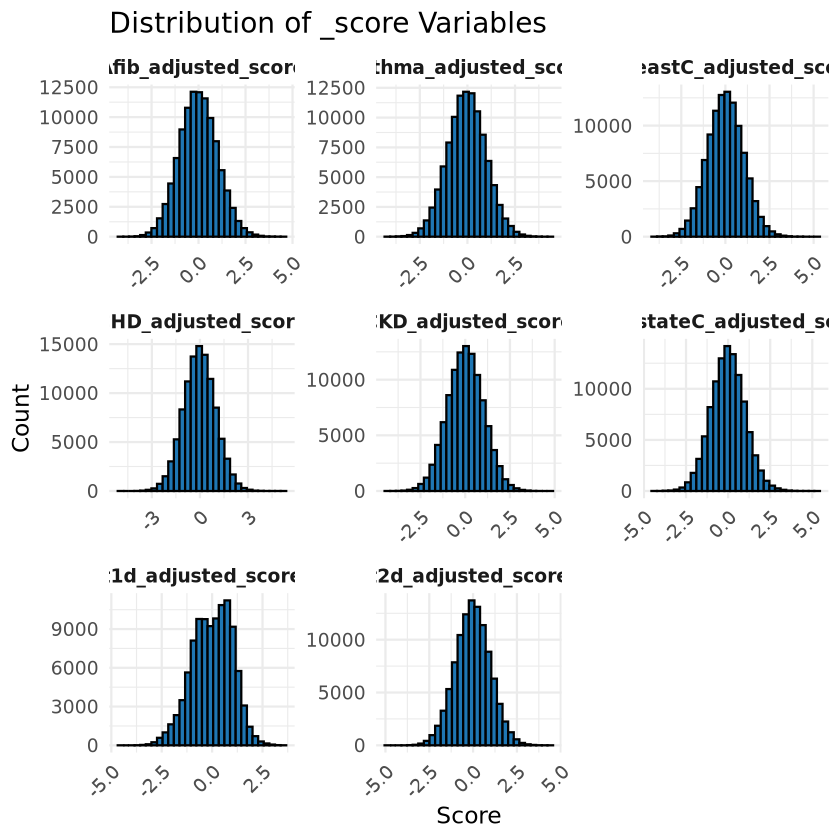

In [5]:
# Gather all _score columns into long format
merged_long <- merged_data %>%
  pivot_longer(
    cols = ends_with("_score"),
    names_to = "Score_Type",
    values_to = "Score_Value"
  )

# Plot faceted histograms
ggplot(merged_long, aes(x = Score_Value)) +
  geom_histogram(bins = 30, fill = "#1f77b4", color = "black") +
  facet_wrap(~ Score_Type, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(
    x = "Score",
    y = "Count",
    title = "Distribution of _score Variables"
  ) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )


In [6]:
merged_data <- merged_data %>%
  mutate(
    SexGenderCis_male = ifelse(SexGender == "Cis_male", 1, 0),
    SexGenderCis_female = ifelse(SexGender == "Cis_female", 1, 0),
    SexGenderSGM = ifelse(SexGender == "SGM", 1, 0)
  )

merged_data$age2 <- merged_data$age^2

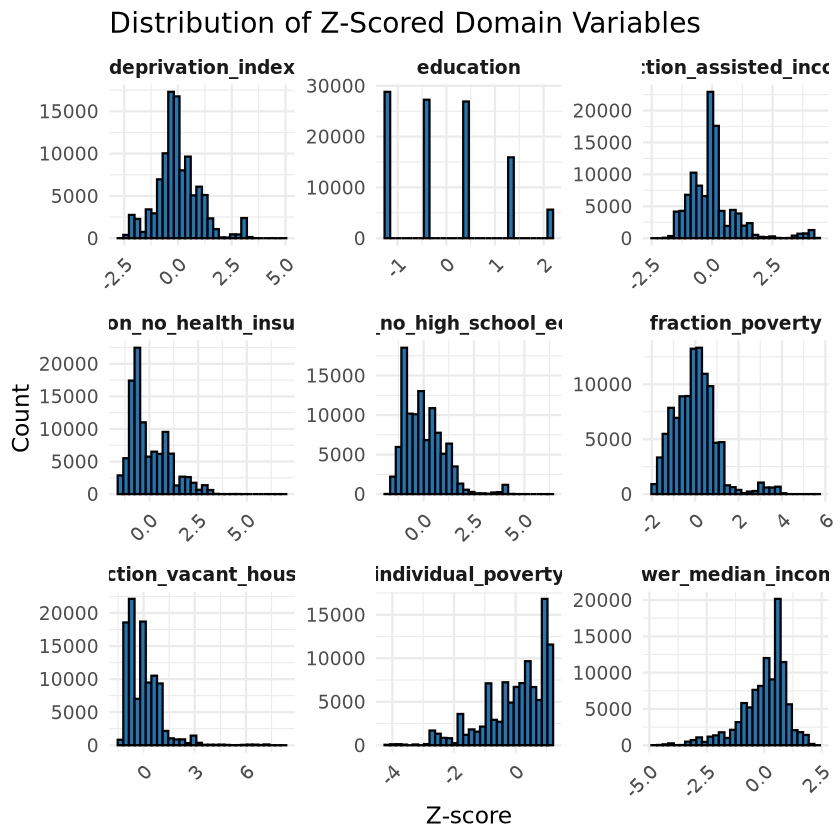

In [7]:
# Z-score normalize the domain columns
merged_z <- merged_data %>%
  mutate(across(all_of(domains), ~ (. - mean(., na.rm = TRUE)) / sd(., na.rm = TRUE)))

# Pivot to long format for plotting
merged_long <- merged_z %>%
  pivot_longer(
    cols = all_of(domains),
    names_to = "Score_Type",
    values_to = "Score_Value"
  )

# Plot faceted histograms
ggplot(merged_long, aes(x = Score_Value)) +
  geom_histogram(bins = 30, fill = "#1f77b4", color = "black") +
  facet_wrap(~ Score_Type, scales = "free") +
  theme_minimal(base_size = 14) +
  labs(
    x = "Z-score",
    y = "Count",
    title = "Distribution of Z-Scored Domain Variables"
  ) +
  theme(
    axis.text.x = element_text(angle = 45, hjust = 1),
    strip.text = element_text(face = "bold")
  )

# Plot effects

In [8]:
ggplot_slopes_flex <- function(
    disease,
    domain,
    data,
    stratify_by = c("domain", "score"),
    x_axis      = c("score", "domain"),
    probs = c(0.1, 0.5, 0.9)
){

  stratify_by <- match.arg(stratify_by)
  x_axis      <- match.arg(x_axis)

  score_col  <- paste0(disease, "_adjusted_score")
  domain_col <- domain
  int_name   <- paste0(score_col, ":", domain_col)

  # ============================================================
  # REQUIRED COLS
  # ============================================================

  req <- c(
    disease, score_col, domain_col,
    "age","age2","record_depth","visit_frequency"
  )

  miss <- setdiff(req, names(data))
  if(length(miss) > 0){
    stop("Missing columns: ", paste(miss, collapse=", "))
  }

  filtered_data <- data

  # ============================================================
  # FILTERING
  # ============================================================

  if(disease %in% c("CKD","t1d")){
    filtered_data <- filtered_data |> dplyr::filter(SexGenderSGM == 0)
  }

  if(disease == "BreastC"){
    filtered_data <- filtered_data |> dplyr::filter(SexGenderCis_female == 1)
  }

  if(disease == "ProstateC"){
    filtered_data <- filtered_data |> dplyr::filter(SexGenderCis_male == 1)
  }

  # ============================================================
  # SEX TERMS
  # ============================================================

  sex_terms <- intersect(
    c("SexGenderCis_male","SexGenderSGM"),
    names(filtered_data)
  )

  if(disease %in% c("CKD","t1d")){
    sex_terms <- setdiff(sex_terms,"SexGenderSGM")
  }

  if(disease %in% c("BreastC","ProstateC")){
    sex_terms <- character(0)
  }

  model_vars <- c(
    "age","age2","record_depth","visit_frequency",
    sex_terms, score_col, domain_col
  )

  filtered_data <- filtered_data |>
    dplyr::filter(
      dplyr::if_all(dplyr::all_of(model_vars), ~ !is.na(.))
    )

  # ============================================================
  # MODEL
  # ============================================================

  rhs <- c(
    "age","age2","record_depth","visit_frequency",
    sex_terms,
    score_col,
    domain_col,
    int_name
  )

  fmla <- as.formula(
    paste(disease, "~", paste(rhs, collapse=" + "))
  )

  model <- glm(fmla, data=filtered_data, family=binomial())

  # ============================================================
  # X AXIS
  # ============================================================

  if(x_axis == "score"){
    x_var <- score_col
    x_vals <- seq(
      min(filtered_data[[score_col]], na.rm=TRUE),
      max(filtered_data[[score_col]], na.rm=TRUE),
      length.out=100
    )
  } else {
    x_var <- domain_col
    x_vals <- seq(
      min(filtered_data[[domain_col]], na.rm=TRUE),
      max(filtered_data[[domain_col]], na.rm=TRUE),
      length.out=100
    )
  }

  # ============================================================
  # STRATIFICATION
  # ============================================================

  if(stratify_by == "score"){
    strat_var <- score_col
    strat_vals <- quantile(
      filtered_data[[score_col]],
      probs=probs,
      na.rm=TRUE,
      names=FALSE
    )
  } else {
    strat_var <- domain_col
    strat_vals <- quantile(
      filtered_data[[domain_col]],
      probs=probs,
      na.rm=TRUE,
      names=FALSE
    )
  }

  # ============================================================
  # GRID
  # ============================================================

  pred_grid <- expand.grid(
    x_tmp = x_vals,
    strat_tmp = strat_vals
  )

  pred_grid[[x_var]]     <- pred_grid$x_tmp
  pred_grid[[strat_var]] <- pred_grid$strat_tmp

  pred_grid <- pred_grid |>
    dplyr::mutate(
      group = dplyr::case_when(
        strat_tmp == strat_vals[1] ~ "Low",
        strat_tmp == strat_vals[2] ~ "Medium",
        TRUE ~ "High"
      ),
      group = factor(group, levels=c("Low","Medium","High")),

      age = median(filtered_data$age, na.rm=TRUE),
      age2 = median(filtered_data$age2, na.rm=TRUE),
      record_depth = median(filtered_data$record_depth, na.rm=TRUE),
      visit_frequency = median(filtered_data$visit_frequency, na.rm=TRUE)
    )

  for(term in sex_terms) pred_grid[[term]] <- 0

  pred_grid$x_tmp <- NULL
  pred_grid$strat_tmp <- NULL

  # ============================================================
  # PREDICT
  # ============================================================

  pred <- predict(model, newdata=pred_grid, type="link", se.fit=TRUE)

  pred_grid <- pred_grid |>
    dplyr::mutate(
      fit_link = pred$fit,
      se_link = pred$se.fit,
      fit_prob = plogis(fit_link),
      lower_prob = plogis(fit_link - 1.96*se_link),
      upper_prob = plogis(fit_link + 1.96*se_link)
    )

  # ============================================================
  # SLOPES
  # ============================================================

  slopes <- pred_grid |>
    dplyr::group_by(group) |>
    dplyr::summarise(
      slope = coef(lm(fit_prob ~ .data[[x_var]]))[2],
      .groups="drop"
    )

  intercepts <- pred_grid |>
    dplyr::group_by(group) |>
    dplyr::summarise(
      intercept = mean(fit_prob),
      .groups="drop"
    )

  slope_low  <- slopes$slope[slopes$group == "Low"]
  slope_high <- slopes$slope[slopes$group == "High"]
  slope_diff <- slope_high - slope_low
  intercept_low <- intercepts$intercept[intercepts$group == "Low"]
  intercept_high <- intercepts$intercept[intercepts$group == "High"]


  coef_summary <- summary(model)$coefficients
    
  se_int <- if (int_name %in% rownames(coef_summary)) {
      coef_summary[int_name, "Std. Error"]
    } else {
      NA_real_
    }

  # uncertainty approximation
  se_diff <- if (!is.na(se_int)) abs(se_int) else NA_real_

  z_diff <- if (!is.na(se_diff) && se_diff > 0) slope_diff / se_diff else NA_real_
  p_diff <- if (!is.na(z_diff)) 2 * pnorm(-abs(z_diff)) else NA_real_

  bonf_sig <- if (!is.na(p_diff)) p_diff < (0.05 / nrow(combos)) else FALSE


  slopes_df <- data.frame(
      disease = disease,
      domain  = domain,

      intercept_low  = intercept_low,
      intercept_high = intercept_high,

      slope_low  = slope_low,
      slope_high = slope_high,
      slope_diff = slope_diff,

      one_sd_prob_low  = intercept_low + slope_low,
      one_sd_prob_high = intercept_high + slope_high,

      se_diff    = se_diff,
      z_diff     = z_diff,
      p_slope_diff = p_diff,
      bonf_sig   = bonf_sig
    )
  

  # ============================================================
  # LABELS
  # ============================================================

  x_min <- min(pred_grid[[x_var]], na.rm=TRUE)
  x_max <- max(pred_grid[[x_var]], na.rm=TRUE)

  y_low  <- quantile(pred_grid$fit_prob, .05)
  y_high <- quantile(pred_grid$fit_prob, .95)

  label_positions <- slopes |>
    dplyr::filter(group %in% c("Low","High")) |>
    dplyr::mutate(
      x = ifelse(group=="High", x_min, x_max),
      y = ifelse(group=="High", y_high, y_low),
      hjust = ifelse(group=="High",0,1),
      vjust = ifelse(group=="High",1,0),
      label = round(slope,3)
    )

  # ============================================================
  # OR TABLE
  # ============================================================

  coefs <- summary(model)$coefficients
  int_term <- paste0(score_col,":",domain_col)

  beta_int <- if(int_term %in% rownames(coefs)) coefs[int_term,"Estimate"] else 0
  se_int   <- if(int_term %in% rownames(coefs)) coefs[int_term,"Std. Error"] else 0

  if(stratify_by == "domain"){

    beta_main <- coefs[score_col,"Estimate"]
    se_main   <- coefs[score_col,"Std. Error"]
    sd_main   <- sd(filtered_data[[score_col]], na.rm=TRUE)

    vals <- quantile(filtered_data[[domain_col]], probs, na.rm=TRUE)

    OR <- data.frame(
      Disease = disease,
      Domain = domain_col,
      group = c("Low","Medium","High"),
      modifier = vals
    ) |>
    dplyr::mutate(
      beta = beta_main + beta_int*modifier,
      se_beta = sqrt(se_main^2 + (modifier^2 * se_int^2)),

      OR_per_SD = exp(beta * sd_main),
      OR_lower  = exp((beta - 1.96*se_beta) * sd_main),
      OR_upper  = exp((beta + 1.96*se_beta) * sd_main),
        
      age             = median(filtered_data$age, na.rm = TRUE),
      age2            = median(filtered_data$age2, na.rm = TRUE),
      record_depth    = median(filtered_data$record_depth, na.rm = TRUE),
      visit_frequency = median(filtered_data$visit_frequency, na.rm = TRUE)
    )

    for (term in sex_terms) OR[[term]] <- 0  
    OR[[domain_col]] <- OR$modifier

    OR0 <- OR
    OR1 <- OR

    OR0[[score_col]] <- 0
    OR1[[score_col]] <- sd_main

    OR$prob_PRS0 <- predict(model, newdata = OR0, type = "response")
    OR$prob_PRS1SD <- predict(model, newdata = OR1, type = "response")

    OR <- OR |>
      dplyr::mutate(
        abs_risk = prob_PRS1SD - prob_PRS0,
        rel_risk = ifelse(prob_PRS0 > 0,
                        (prob_PRS1SD - prob_PRS0) / prob_PRS0,
                        NA_real_))  

  } else {

    beta_main <- coefs[domain_col,"Estimate"]
    se_main   <- coefs[domain_col,"Std. Error"]
    sd_main   <- sd(filtered_data[[domain_col]], na.rm=TRUE)

    vals <- quantile(filtered_data[[score_col]], probs, na.rm=TRUE)

    OR <- data.frame(
      Disease = disease,
      Domain = domain_col,
      group = c("Low","Medium","High"),
      modifier = vals
    ) 
    OR <- OR |>
    dplyr::mutate(
      beta = beta_main + beta_int*modifier,
      se_beta = sqrt(se_main^2 + (modifier^2 * se_int^2)),

      OR_per_SD = exp(beta * sd_main),
      OR_lower  = exp((beta - 1.96*se_beta) * sd_main),
      OR_upper  = exp((beta + 1.96*se_beta) * sd_main),
        
      age             = median(filtered_data$age, na.rm = TRUE),
      age2            = median(filtered_data$age2, na.rm = TRUE),
      record_depth    = median(filtered_data$record_depth, na.rm = TRUE),
      visit_frequency = median(filtered_data$visit_frequency, na.rm = TRUE)
    )
      
    for (term in sex_terms) OR[[term]] <- 0
    OR[[score_col]] <- OR$modifier

      
    OR0 <- OR
    OR1 <- OR

    OR0[[domain_col]] <- 0
    OR1[[domain_col]] <- sd_main

    OR$prob_SDoH0 <- predict(model, newdata = OR0, type = "response")
    OR$prob_SDoH1SD <- predict(model, newdata = OR1, type = "response")

    OR <- OR |>
      dplyr::mutate(
        abs_risk = prob_SDoH1SD - prob_SDoH0,
        rel_risk = ifelse(prob_SDoH0 > 0,
                        (prob_SDoH1SD - prob_SDoH0) / prob_SDoH0,
                        NA_real_))  
  }



  # ============================================================
  # RETURN
  # ============================================================

  list(
    pred_grid   = pred_grid,
    slopes      = slopes_df,
    labels      = label_positions,
    model       = model,
    x_var       = x_var,
    strat_var   = strat_var,
    coef        = OR,
    intercepts  = intercepts
  )         
}

In [9]:
# ============================================================
# Batch runner
# ============================================================

generate_plots_flex <- function(
    combos,
    data,
    stratify_by = c("domain", "score"),
    x_axis      = c("score", "domain")) {

  stratify_by <- match.arg(stratify_by)
  x_axis      <- match.arg(x_axis)

  # --------------------------------------------------
  # storage objects
  # --------------------------------------------------
  plot_list       <- list()
  slopes_list     <- list()
  coef_list       <- list()
  model_list      <- list()
  slope_diff_list <- list()

  # --------------------------------------------------
  # loop through disease/domain combos
  # --------------------------------------------------
  for(i in seq_len(nrow(combos))){

    disease <- combos$disease[i]
    domain  <- combos$domain[i]

    nm <- paste(disease, domain, sep = "_")

    res <- tryCatch(
      ggplot_slopes_flex(
        disease     = disease,
        domain      = domain,
        data        = data,
        stratify_by = stratify_by,
        x_axis      = x_axis
      ),
      error = function(e){
        message("Failed: ", nm, " | ", e$message)
        NULL
      }
    )

    if(is.null(res)) next

    # -----------------------------
    # store components
    # -----------------------------
    plot_list[[nm]]   <- res$pred_grid
    slopes_list[[nm]] <- res$slopes
    coef_list[[nm]]   <- res$coef
    model_list[[nm]]  <- res$model
      
}


  # --------------------------------------------------
  # return structured output
  # --------------------------------------------------
  list(
    plots      = plot_list,
    slopes     = slopes_list,
    coef       = coef_list,
    model      = model_list
  )
}


In [10]:
# Standard:
# PRS on x-axis, domain stratified
results1 <- generate_plots_flex(
  combos,
  merged_z,
  stratify_by = "domain",
  x_axis = "score"
)

# Access all plots
plot_list <- results1$plots

# Access all slopes list
slopes_list <- results1$slopes

model_lists <- results1$model


coef<-results1$coef

coef_df <- do.call(rbind, lapply(names(coef), function(name) {

  mat <- coef[[name]]
  
  data.frame(
    model = name,
    Disease =  mat[, "Disease"],
    Domain =  mat[, "Domain"], 
    group = rownames(mat),
    modifier_value = mat[, "modifier"],
    Beta = mat[, "beta"],
    Se_beta = mat[, "se_beta"],
    OR_per_SD = mat[, "OR_per_SD"],
    OR_lower = mat[, "OR_lower"],
    OR_upper = mat[, "OR_upper"],
    prob_PRS0 = mat[, "prob_PRS0"],
    prob_PRS1SD = mat[, "prob_PRS1SD"],
    abs_risk_increase_SD = mat[, "abs_risk"],
    rel_risk_increase_SD = mat[, "rel_risk"],
    row.names = NULL
  )
}))

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”
Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


In [11]:
#Save table
write_excel_csv(coef_df, file.path(output_dir, "conditional_effects.csv"))

slopes_df <- dplyr::bind_rows(
  lapply(names(slopes_list), function(nm) {

    df <- as.data.frame(slopes_list[[nm]], row.names = NULL)

    parts <- strsplit(nm, "_")[[1]]

    df$disease <- parts[1]
    df$domain  <- paste(parts[-1], collapse = "_")
    df$model   <- nm

    df
  }),
  .id = NULL
) |>
  tibble::as_tibble()

#Save table
write_excel_csv(slopes_df, file.path(output_dir, "slope_effects.csv"))

# Plot changes in risk

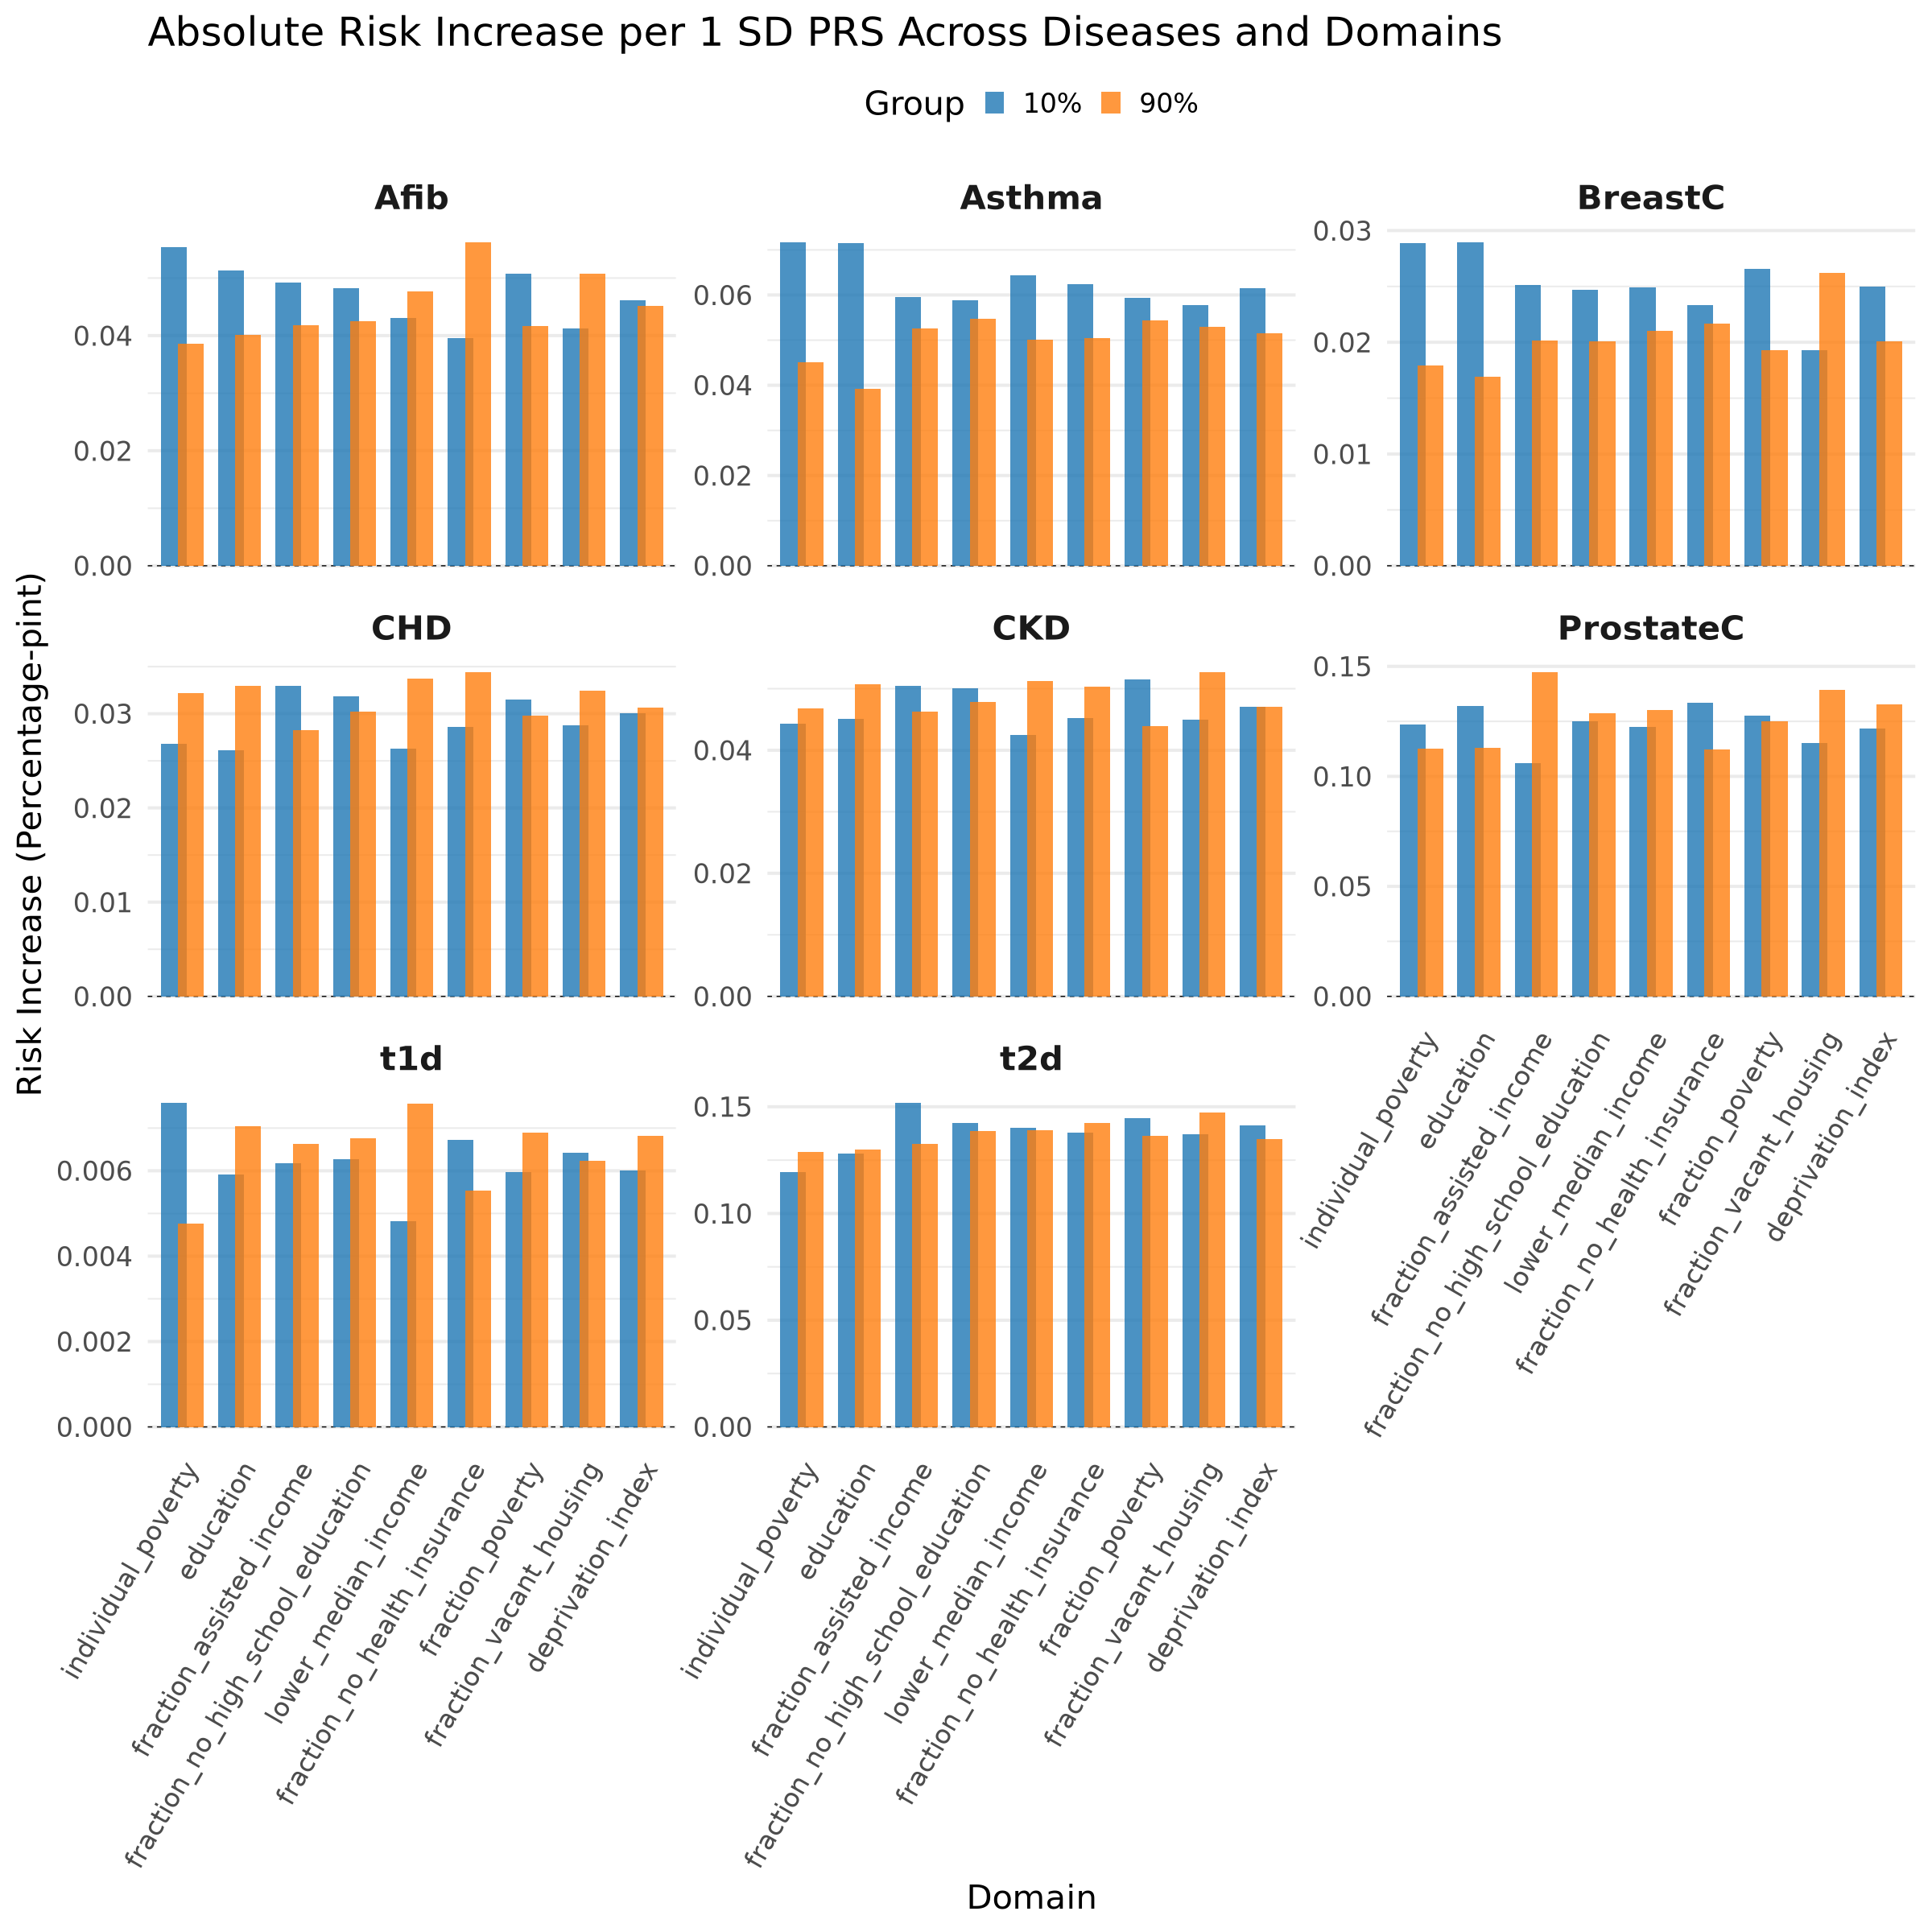

In [12]:
options(repr.plot.width = 20, repr.plot.height = 20)  # Set width and height


coef_df_plot <- coef_df %>%
  mutate(
    group = factor(group, levels = c("10%", "90%")),
    Domain = factor(Domain, levels = unique(Domain))
  ) %>%
  filter(group %in% c("10%", "90%"))

abs_risk_plot <- ggplot(
  coef_df_plot,
  aes(
    x = Domain,
    y = abs_risk_increase_SD,
    fill = group
  )
) +
  geom_hline(yintercept = 0, linetype = "dashed", linewidth = 0.4) +
  geom_col(
    position = position_dodge(width = 0.6),
    alpha = 0.8
  ) +
  facet_wrap(~ Disease, scales = "free_y") +
  scale_fill_manual(
    values = c(
      "10%" = "#1f77b4",
      "90%" = "#ff7f0e"
    )
  ) +
  labs(
    x = "Domain",
    y = "Risk Increase (Percentage-pint)",
    fill = "Group",
    title = "Absolute Risk Increase per 1 SD PRS Across Diseases and Domains"
  ) +
  theme_minimal(base_size = 25) +
  theme(
    legend.position = "top",
    axis.text.x = element_text(angle = 60, hjust = 1),
    strip.text = element_text(face = "bold", size = 25),
    panel.grid.major.x = element_blank()
  )

abs_risk_plot

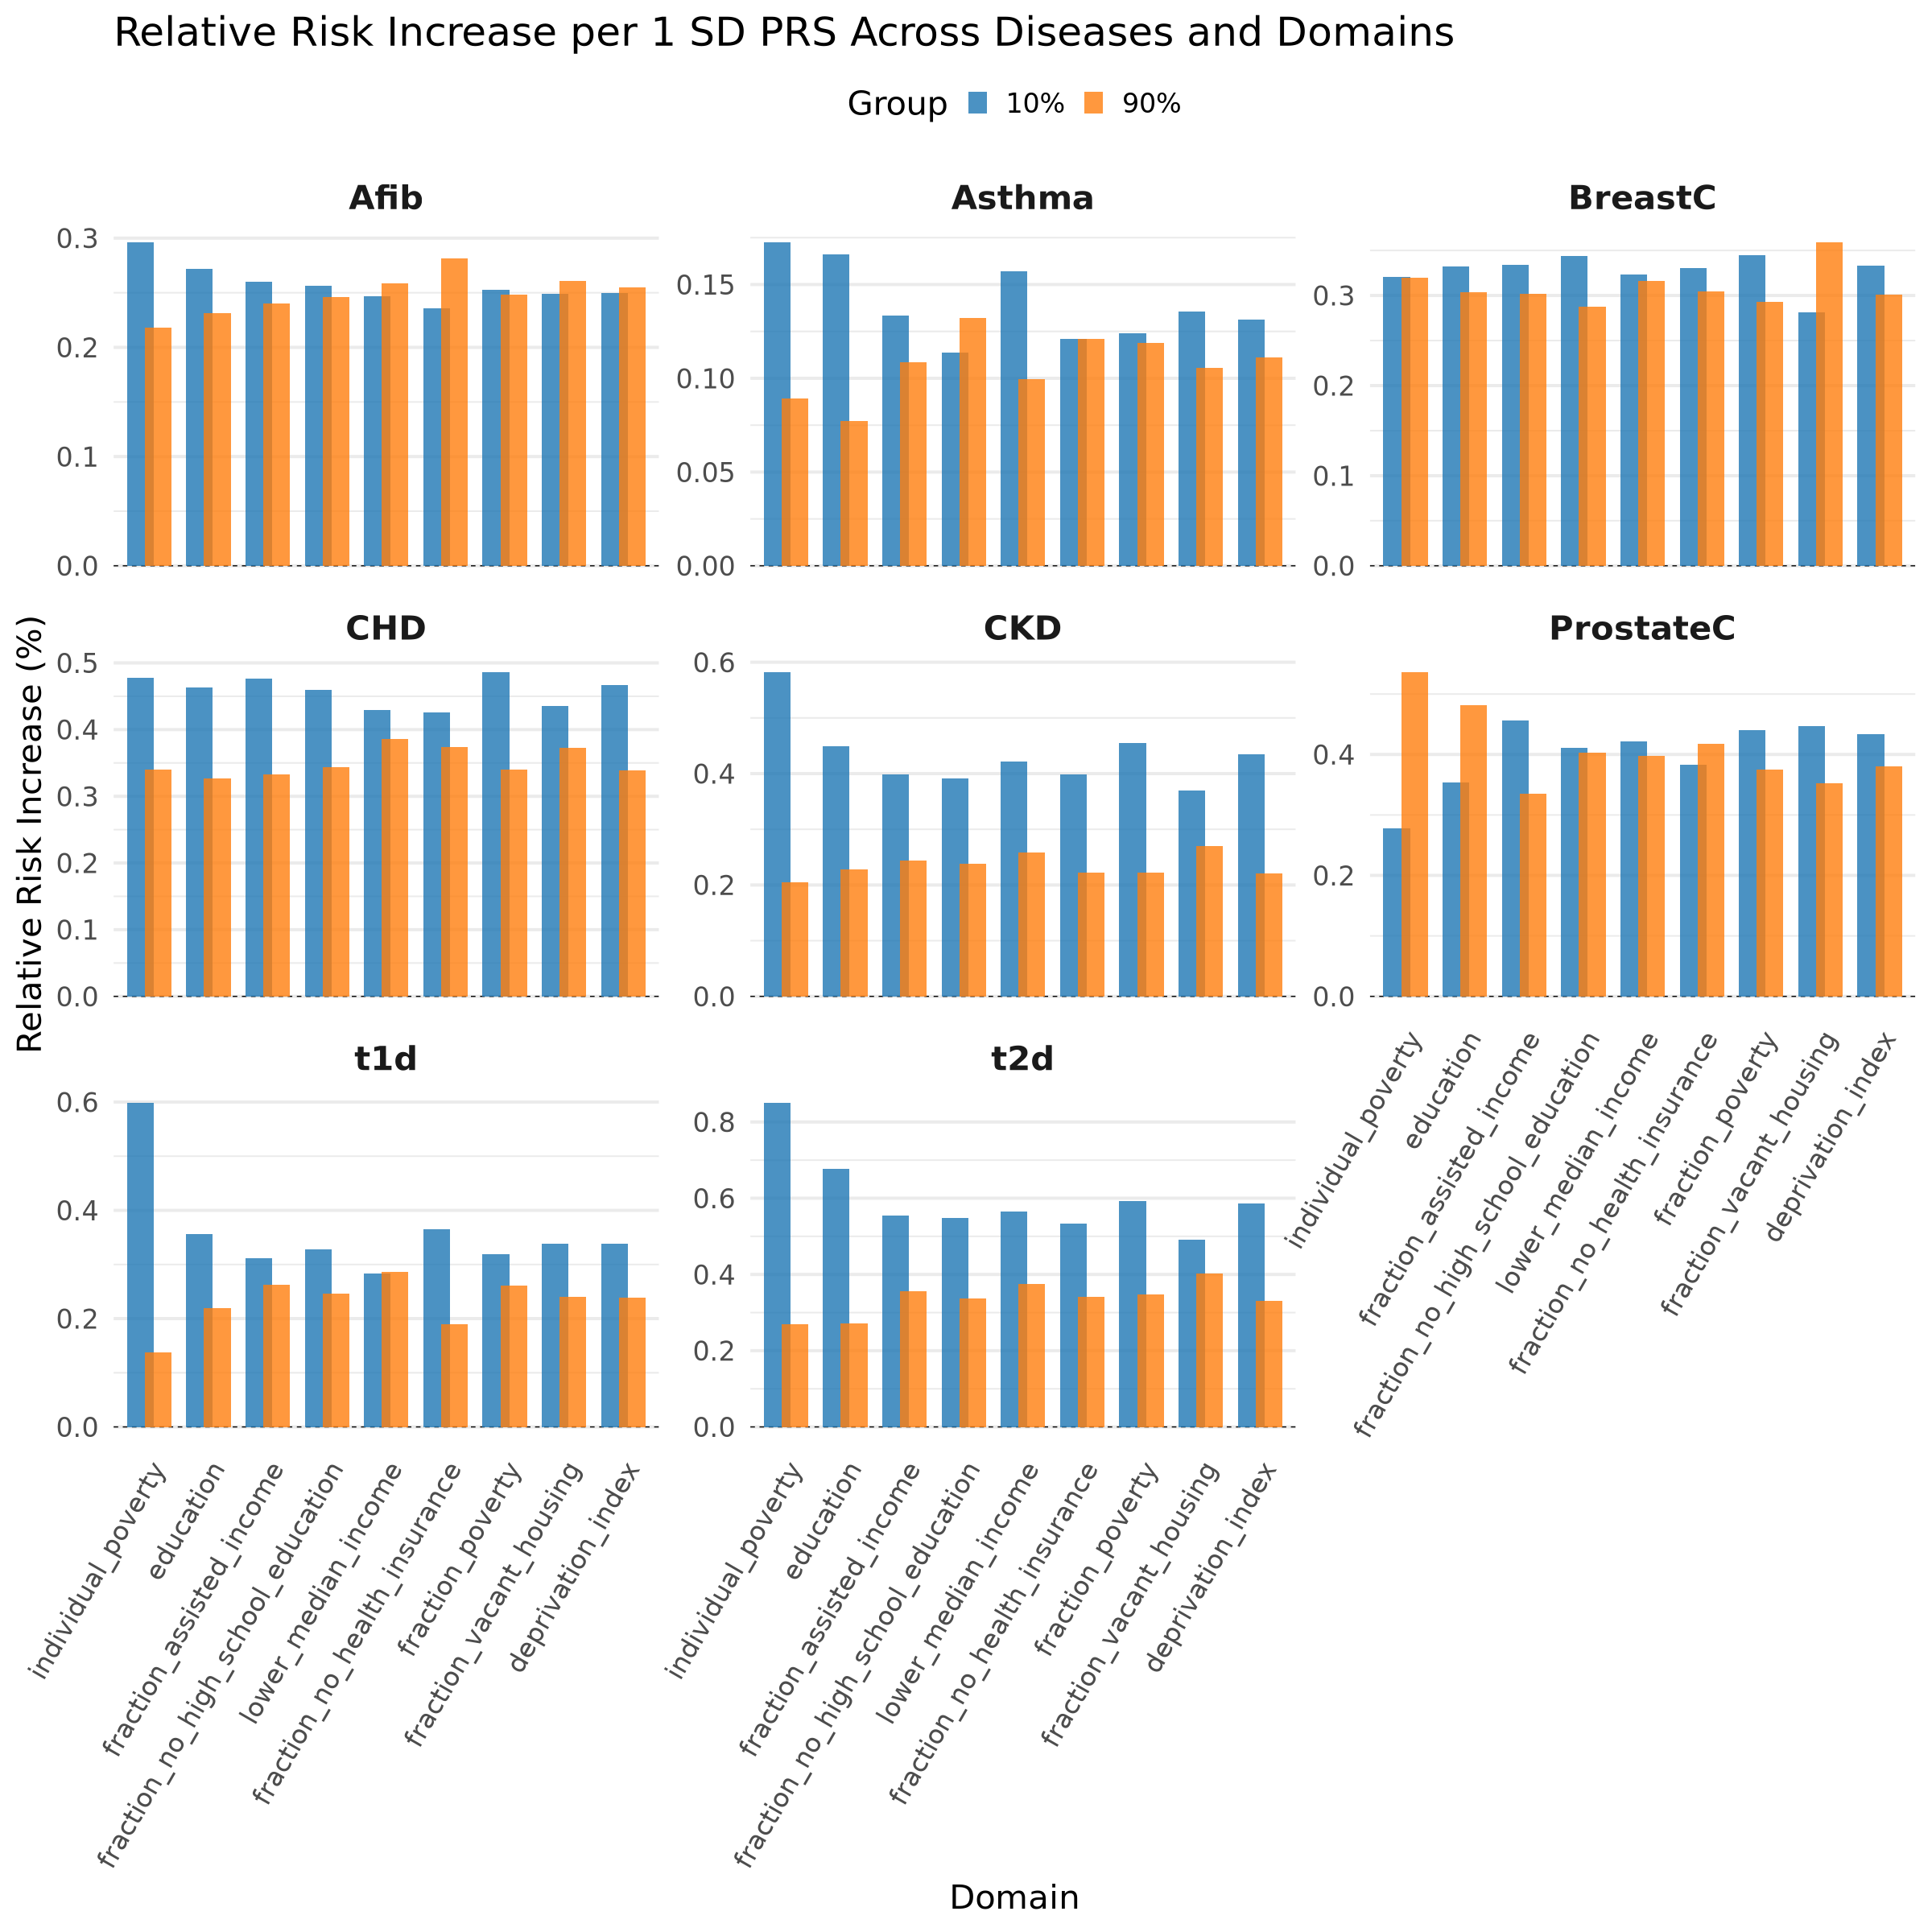

In [13]:
rel_risk_plot <- ggplot(
  coef_df_plot,
  aes(
    x = Domain,
    y = rel_risk_increase_SD,
    fill = group
  )
) +
  geom_hline(yintercept = 0, linetype = "dashed", linewidth = 0.4) +
  geom_col(
    position = position_dodge(width = 0.6),
    alpha = 0.8
  ) +
  facet_wrap(~ Disease, scales = "free_y") +
  scale_fill_manual(
    values = c(
      "10%" = "#1f77b4",
      "90%" = "#ff7f0e"
    )
  ) +
  labs(
    x = "Domain",
    y = "Relative Risk Increase (%)",
    fill = "Group",
    title = "Relative Risk Increase per 1 SD PRS Across Diseases and Domains"
  ) +
  theme_minimal(base_size = 25) +
  theme(
    legend.position = "top",
    axis.text.x = element_text(angle = 60, hjust = 1),
    strip.text = element_text(face = "bold", size = 25),
    panel.grid.major.x = element_blank()
  )

rel_risk_plot

In [14]:
plot_list$t2d_deprivation_index[150,]

,t2d_adjusted_score,deprivation_index,group,age,age2,record_depth,visit_frequency,SexGenderCis_male,SexGenderSGM,fit_link,se_link,fit_prob,lower_prob,upper_prob
,<dbl>,<dbl>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
150,-0.29044,-0.100143,Medium,60,3600,99,0.02185417,0,0,-0.98922,0.01764283,0.2710662,0.2642879,0.2779526


In [15]:
plot_interaction <- function(pred_grid, slopes_df, x_var, y_label, x_label, legend_label, breaks, y_lims) {
  
  x_col <- rlang::sym(x_var)  # allow dynamic x-axis variable
  
  ggplot(pred_grid, aes(
    x = !!x_col,
    y = fit_prob,
    color = group,   # line color
    fill  = group    # ribbon fill
  )) +
    geom_line(size = 1.2) +
    geom_ribbon(
      aes(ymin = lower_prob, ymax = upper_prob),
      alpha = 0.2,
      color = NA
    ) +
    theme_bw(base_size = 14) +
    scale_y_continuous(
      trans = scales::logit_trans(),
      breaks = breaks,
      labels = scales::percent,
       limits = y_lims
    ) +
    scale_color_manual(values = model_colors) +
    scale_fill_manual(values = model_colors) +
    labs(
      title = "",
      x = x_label,
      y = y_label,
      color = legend_label,
      fill = legend_label
    ) +
    theme(
       legend.position = "none",
      axis.title.x = element_text(size = 16, face = "bold", angle = 0),
      axis.title.y = element_text(size = 16, face = "bold")
    ) 
}

In [16]:
social_name_mapping <- c(
  "individual_poverty" = " Individual \nPoverty",
  "education" = "Individual\nEducation",
  "fraction_assisted_income" = "Assisted\nIncome (%)",
  "fraction_no_high_school_education" = "High School\nEducation (%)",
  "lower_median_income" = " Median\nArea Income ",
  "fraction_no_health_insurance" = "Health\nInsurance (%)",
  "fraction_poverty" = "Poverty (%)", 
  "fraction_vacant_housing" = "Vacant\nHousing (%)",
  "deprivation_index" = "Deprivation\nIndex"
)

disease_name_mapping <-c(
    "Asthma" = "Asthma", 
    "Afib" = "Afib",
    "BreastC" = "Breast Cancer",
    "CKD" = "CKD",
    "CHD" = "CHD",
    "ProstateC" = "Prostate Cancer",
    "t2d" = "T2D",
    "t1d" = "T1D"

)

breaks_mapping <- list(
  Asthma     = c(0.2, 0.4, 0.6, 0.8), 
  Afib       = c(0.02, 0.05, 0.1, 0.2, 0.4),
  BreastC    = c(0.01, 0.02, 0.05, 0.1, 0.2, .4),
  CKD        = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4), 
  CHD        = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4), 
  ProstateC  = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8), 
  t2d        = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8), 
  t1d        = c(0.005, 0.01, 0.02, 0.05, 0.1)
)

y_lims_mapping <- list(
  Asthma     = c(0.2, .8), 
  Afib       = c(0.02, 0.4),
  BreastC    = c(0.01,.4),
  CKD        = c(0.01, 0.4), 
  CHD        = c(0.01, 0.4), 
  ProstateC  = c(0.01,0.8), 
  t2d        = c(0.01, 0.8), 
  t1d        = c(0.005, 0.1)
)

# Add readable SDoH names using social_name_mapping
combos$SDoH <- social_name_mapping[combos$domain]

# Add readable disease names using disease_name_mapping
combos$Disease <- disease_name_mapping[combos$disease]

# Add readable disease names using disease_name_mapping
combos$breaks <- sapply(combos$disease, function(d) breaks_mapping[[d]], simplify = FALSE)
                        
combos$y_lims <- sapply(combos$disease, function(d) y_lims_mapping[[d]], simplify = FALSE)

In [17]:
generate_interaction_plots <- function(combos, plot_list, slopes_list) {
  # Initialize list to store plots
  interaction_plots <- list()
  
  for(i in seq_len(nrow(combos))) {
    row <- combos[i, ]
    
    # Skip if corresponding plot or slope data is missing
    plot_name <- paste(row$disease, row$domain, sep = "_")
    if(is.null(plot_list[[plot_name]]) | is.null(slopes_list[[plot_name]])) next
    
    pred_grid <- plot_list[[plot_name]]
    slopes_df <- slopes_list[[plot_name]]
    
    # Labels
    y_label <- row$Disease
    #x_label <- NULL
    legend_label <- NULL 
    x_label <- row$SDoH
    #y_label <- NULL
    
    # Breaks
    breaks_vals <- breaks_mapping[[row$disease]] 
    y_lims <- y_lims_mapping[[row$disease]] 
    
    # Generate plot
    p <- plot_interaction(
      pred_grid = pred_grid,
      slopes_df = slopes_df,
      x_var = paste0(row$disease, "_adjusted_score"),
      y_label = y_label,
      x_label = x_label,
      legend_label = "legend_label",
      breaks = breaks_vals,
      y_lims = y_lims
    )

    
    # Store in list
    interaction_plots[[plot_name]] <- p
  }
  
  return(interaction_plots)
}

interaction_plots <- generate_interaction_plots(combos, plot_list, slopes_list)

Warning message:
“Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.”


Warning message:
“Removed 22 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 36 rows containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 21 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 36 rows containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 32 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 43 rows containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 23 rows containing missing values or values outside the scale range
(`geom_line()`).”
Warning message:
“Removed 37 rows containing missing values or values outside the scale range
(`geom_ribbon()`).”
Warning message:
“Removed 22 rows containing missing values or values outside the scale range
(`

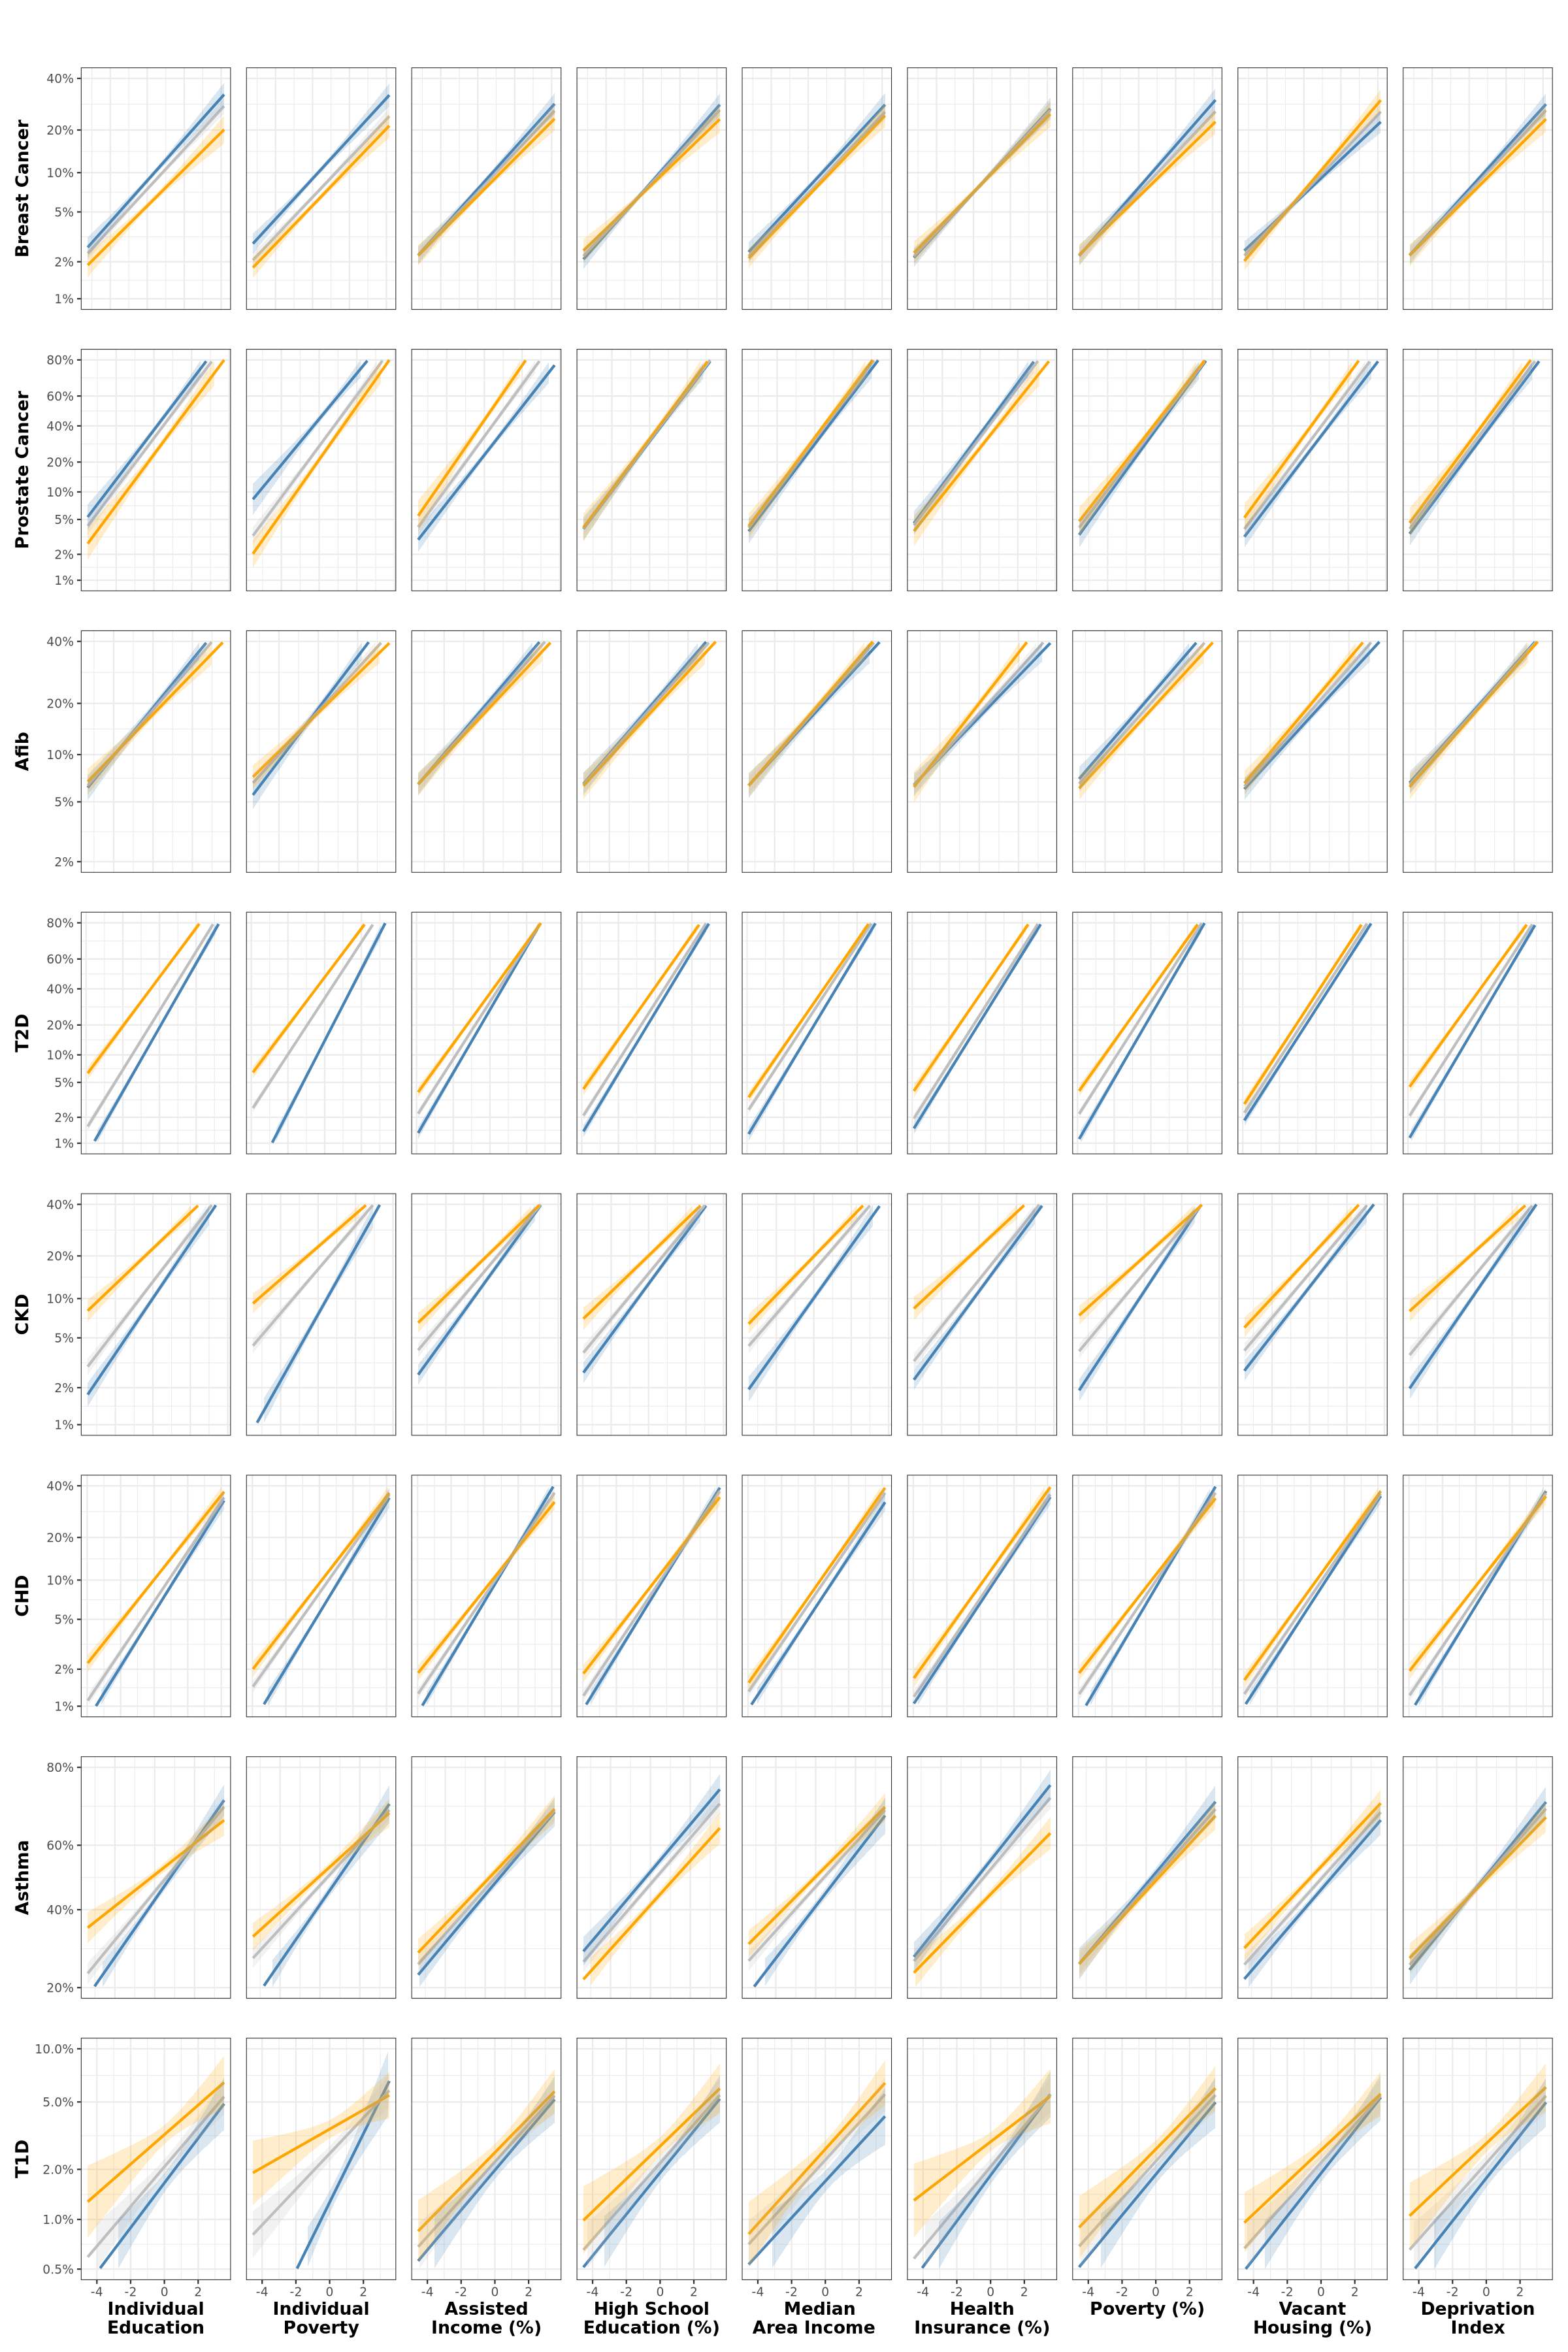

In [18]:
options(repr.plot.width = 20, repr.plot.height = 30)  # Set width and height


x_axis_order <- c('Individual\nEducation', ' Individual \nPoverty','Assisted\nIncome (%)',
           'High School\nEducation (%)', ' Median\nArea Income ',
           'Health\nInsurance (%)', 'Poverty (%)', 'Vacant\nHousing (%)', 'Deprivation\nIndex')


y_axis_order <-c("Breast Cancer", "Prostate Cancer", "Afib", "T2D", "CKD", "CHD", "Asthma", "T1D")


# Convert list to tibble
plots_df <- tibble(
  plot_name = names(interaction_plots),
  plot = interaction_plots
) %>%
  # Split plot_name back to disease and SDoH
  mutate(
    disease_code = sapply(strsplit(plot_name, "_"), `[`, 1),
    domain_code  = sapply(strsplit(plot_name, "_"), `[`, 2),
    Disease = disease_name_mapping[disease_code],
    SDoH = social_name_mapping[domain_code]
  )

plots_df <- plots_df %>%
  mutate(
    Disease = factor(Disease, levels = y_axis_order),
    SDoH = factor(SDoH, levels = x_axis_order)
  ) %>%
  arrange(Disease, SDoH) %>%
   pull(plot)

ncol <- length(x_axis_order)
nrow <- ceiling(length(plots_df) / ncol)

plots_clean <- lapply(seq_along(plots_df), function(i) {
  p <- plots_df[[i]]
  
  row <- ceiling(i / ncol)
  col <- i %% ncol
  if (col == 0) col <- ncol
    
  
  p +
    theme(
      # Remove y-axis except leftmost column
      axis.title.y = if (col == 1) element_text() else element_blank(),
      axis.text.y  = if (col == 1) element_text() else element_blank(),
      axis.ticks.y = if (col == 1) element_line() else element_blank(),
      
      # Remove x-axis except bottom row
      axis.title.x = if (row == nrow) element_text() else element_blank(),
      axis.text.x  = if (row == nrow) element_text() else element_blank(),
      axis.ticks.x = if (row == nrow) element_line() else element_blank()
    ) 
})

final_grid <- wrap_plots(plots_clean, ncol = ncol) +
  plot_annotation(
    title = " ",
    theme = theme(plot.title = element_text(size = 20, face = "bold"))
  )


# Display
final_grid

# Plot examples

In [19]:
plot_interaction2 <- function(pred_grid, slopes_df, x_var, y_label, x_label, legend_label, breaks) {
  
  x_col <- rlang::sym(x_var)  # allow dynamic x-axis variable
    
  slopes_df <- slopes_df |>
  dplyr::select(
    disease, domain,
    intercept_low, intercept_high,
    slope_low, slope_high,
    one_sd_prob_low, one_sd_prob_high,
    slope_diff, se_diff, z_diff,
    p_slope_diff, bonf_sig
  ) |>
  tidyr::pivot_longer(
    cols = c(
      intercept_low, intercept_high,
      slope_low, slope_high,
      one_sd_prob_low, one_sd_prob_high
    ),
    names_to = c(".value", "group"),
    names_pattern = "(intercept|slope|one_sd_prob)_(low|high)"
  ) |>
  dplyr::mutate(
    group = dplyr::recode(
      group,
      low  = "Low",
      high = "High"
    ),
    group = factor(group, levels = c("Low", "High"))
  ) |>
  dplyr::arrange(disease, domain, group) |>
  dplyr::mutate(label = round(slope,3))
        
  x_min <- min(pred_grid[[x_var]], na.rm = TRUE)
  x_max <- max(pred_grid[[x_var]], na.rm = TRUE)

  y_min <- min(pred_grid$fit_prob, na.rm = TRUE)
  y_max <- max(pred_grid$fit_prob, na.rm = TRUE)

  slopes_df <- slopes_df |>
    dplyr::mutate(
      x = dplyr::case_when(
      group == "High" ~ x_min,   # upper left
      group == "Low"  ~ x_max
    ),
    y = dplyr::case_when(
      group == "High" ~ y_max,
      group == "Low"  ~ y_min
    ),
    hjust = dplyr::case_when(
      group == "High" ~ 0,
      group == "Low"  ~ 1
    ),
    vjust = dplyr::case_when(
      group == "High" ~ 1,
      group == "Low"  ~ 0
    )
   )
  
  ggplot(pred_grid, aes(
    x = !!x_col,
    y = fit_prob,
    color = group,   # line color
    fill  = group    # ribbon fill
  )) +
    geom_line(size = 1.2) +
    geom_ribbon(
      aes(ymin = lower_prob, ymax = upper_prob),
      alpha = 0.2,
      color = NA
    ) +
    theme_bw(base_size = 14) +
    scale_y_continuous(
      trans = scales::logit_trans(),
      breaks = breaks,
      labels = scales::percent
    ) +
    scale_x_continuous(
    sec.axis = sec_axis( ~ .,
      name = legend_label 
    )
  ) +
    scale_color_manual(values = model_colors) +
    scale_fill_manual(values = model_colors) +
    labs(
      title = "",
      x = x_label,
      y = y_label
    ) +
    theme(
      legend.position = "none",
      axis.title.x = element_text(size = 16, face = "bold"),
      axis.title.y = element_text(size = 16, face = "bold"),
    axis.ticks.x.top  = element_blank(),
      axis.text.x.top   = element_blank()
    ) +
    geom_text(
       data = slopes_df,
       aes(
        x = x,
        y = y,
       label = label,
       color = group,
       hjust = hjust,
       vjust = vjust
    ),
    inherit.aes = FALSE,
    size = 6
)
}

In [20]:
select_combos <- data.frame(disease = c("t2d", "t2d", "t1d", "CKD", "CHD", "Asthma"),
                           domain = c("deprivation_index", "individual_poverty", "individual_poverty",
                           "fraction_poverty", "fraction_assisted_income", "individual_poverty"))


results3 <- generate_plots_flex(
  select_combos,
  merged_z,
  stratify_by = "domain",
  x_axis = "score"
)


# Access all plots
plot_list <- results3$plots

# Access all slopes list
slopes_list <- results3$slopes


Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


In [21]:
examples<-c("t2d_deprivation_index", "t2d_individual_poverty", "t1d_individual_poverty", 
           "CKD_fraction_poverty", "CHD_fraction_assisted_income", "Asthma_individual_poverty")

In [22]:
options(repr.plot.width = 8, repr.plot.height = 8)  # Set width and height


# T2D plot
A_plot<-plot_interaction2(
  pred_grid = plot_list[["t2d_deprivation_index"]],
  slopes_df = slopes_list[["t2d_deprivation_index"]],
  x_var = "t2d_adjusted_score",
  y_label = "Predicted Probability",
  x_label = "T2D PRS",
  legend_label = "Area Deprivation Index     ",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8)
)

# T2D plot
B_plot<-plot_interaction2(
  pred_grid = plot_list[["t2d_individual_poverty"]],
  slopes_df = slopes_list[["t2d_individual_poverty"]],
  x_var = "t2d_adjusted_score",
  y_label = NULL,
  x_label = "T2D PRS",
  legend_label = "Individual Poverty     ",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, .4, .8)
)

# T1D plot
C_plot<-plot_interaction2(
  pred_grid = plot_list[["t1d_individual_poverty"]],
  slopes_df = slopes_list[["t1d_individual_poverty"]],
  x_var = "t1d_adjusted_score",
  y_label = NULL,
  x_label = "T1D PRS",
  legend_label = "Individual Poverty     ",
  breaks = c(0.005, 0.01, 0.02, 0.05, 0.1, 0.2)
)


# CKD plot
E_plot<-plot_interaction2(
  pred_grid = plot_list[["CKD_fraction_poverty"]],
  slopes_df = slopes_list[["CKD_fraction_poverty"]],
  x_var = "CKD_adjusted_score",
  y_label = NULL,
  x_label = "CKD PRS",
  legend_label = "Area Poverty (%)     ",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, .4)
)

# CHD plot
F_plot<- plot_interaction2(
  pred_grid = plot_list[["CHD_fraction_assisted_income"]],
  slopes_df = slopes_list[["CHD_fraction_assisted_income"]],
  x_var = "CHD_adjusted_score",
  y_label = NULL,
  x_label = "CHD PRS",
  legend_label = "Area Assisted Income (%)     ",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4) 
)


# Asthma plot
D_plot<-plot_interaction2(
  pred_grid = plot_list[["Asthma_individual_poverty"]],
  slopes_df = slopes_list[["Asthma_individual_poverty"]],
  x_var = "Asthma_adjusted_score",
  y_label ="Predicted Probability",
  x_label = "Asthma PRS",
  legend_label = "Individual Poverty     ",
  breaks = c(0.05, 0.1, 0.2, .4, .8)
)


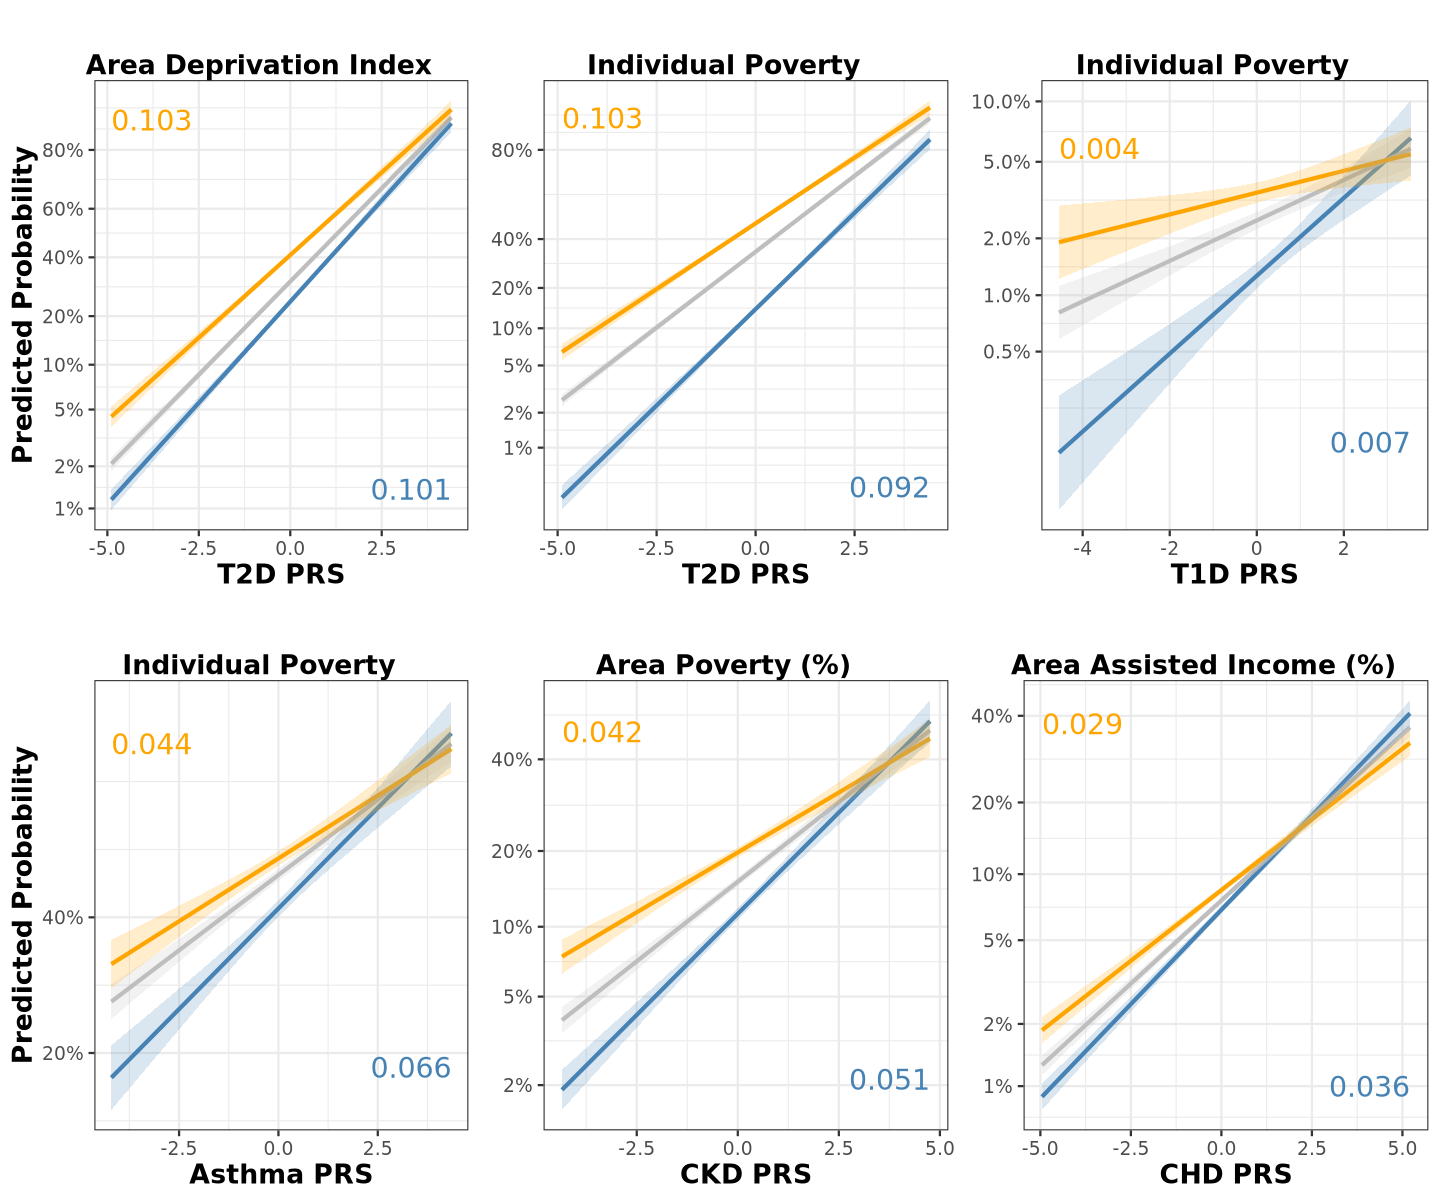

In [23]:
#AB Plot 
library(gridExtra)
library(grid)

options(repr.plot.width = 12, repr.plot.height = 10)  # Set width and height

grid.arrange(
  arrangeGrob(
    A_plot
  ),
  arrangeGrob(
    B_plot 
  
  ),
  arrangeGrob(
    C_plot
  ),
  arrangeGrob(
    D_plot
  ),
  arrangeGrob(
    E_plot
  ),
 arrangeGrob(
    F_plot
  ),
  ncol = 3
)

In [24]:
score_values <- -4:4  # integers of interest

all_slopes_df <- map_dfr(names(plot_list), function(full_name) {
  
  # Extract disease before first underscore
  disease <- sub("_.*", "", full_name)
    
  domain  <- sub("^[^_]+_", "", full_name)
  
  df <- plot_list[[full_name]]
  
  # Dynamically get score column and domain col
  score_col <- paste0(disease, "_adjusted_score")
  domain_col <- domain
    
  
  # Rename to general names
  df <- df %>%
    rename(PRS_value = all_of(score_col),
           domain_value = all_of(domain_col))
  
  df_filtered <- df %>%
    filter(group %in% c("Low", "High")) %>%
    # assign rounded score bins within ±0.1 of integers
    mutate(
      score_round = purrr::map_dbl(PRS_value, function(x) {
        nearest <- score_values[abs(score_values - x) <= 0.1]
        if(length(nearest) == 0) NA_real_ else nearest
      })
    ) %>%
    filter(!is.na(score_round)) %>%  # keep only matched scores
    group_by(group, score_round) %>%
    summarise(across(where(is.numeric), mean, na.rm = TRUE), .groups = "drop")
  
  # Calculate slopes per group
  slopes <- df_filtered %>%
    group_by(group) %>%
    summarise(
      slope_prob = (max(fit_prob) - min(fit_prob)) / 
                   (max(score_round) - min(score_round)),
      slope_link = (max(fit_link) - min(fit_link)) / 
                   (max(score_round) - min(score_round)),
      .groups = "drop"
    )
  
  # Join slopes back and add disease column
  df_filtered %>%
    left_join(slopes, by = "group") %>%
    mutate(disease = disease,
          domain = domain) 
})

all_slopes_df <- all_slopes_df %>% 
    select(-c(age, age2, record_depth, visit_frequency, 
              SexGenderCis_male, SexGenderSGM)) 

Warning message:
“There was 1 warning in `summarise()`.
ℹ In argument: `across(where(is.numeric), mean, na.rm = TRUE)`.
ℹ In group 1: `group = Low`, `score_round = -4`.
Caused by warning:
! The `...` argument of `across()` is deprecated as of dplyr 1.1.0.
Supply arguments directly to `.fns` through an anonymous function instead.

  # Previously
  across(a:b, mean, na.rm = TRUE)

  # Now
  across(a:b, \(x) mean(x, na.rm = TRUE))”


In [25]:
# Define the target probabilities
target_probs <- c(.01, .05, .1, .2, .4, .8, .9)

prob_table_list <- map_dfr(names(plot_list), function(full_name) {
  
  # Extract disease and domain
  disease <- sub("_.*", "", full_name)
  domain  <- sub("^[^_]+_", "", full_name)
  
  df <- plot_list[[full_name]]
    
  domain  <- sub("^[^_]+_", "", full_name)
  
  # Identify score and domain columns
  score_col <- grep("_adjusted_score$", colnames(df), value = TRUE)
  domain_col <- domain
  
  # Rename to general names
  df <- df %>%
    rename(adjusted_score = all_of(score_col),
           domain = all_of(domain_col))
  
  # Filter only Low and High groups
  df <- df %>% filter(group %in% c("Low","High"))
  
  # For each group, interpolate adjusted_score for each target probability
  map_dfr(unique(df$group), function(g) {
    df_group <- df %>% filter(group == g)
    
    # Use approx to interpolate adjusted_score for target probability
    approx_score <- approx(
      x = df_group$fit_prob,
      y = df_group$adjusted_score,
      xout = target_probs,
      rule = 2  # allow extrapolation
    )
    
    data.frame(
      disease = disease,
      domain  = domain,
      group   = g,
      target_prob = approx_score$x,
      required_score = approx_score$y
    )
  })
})


In [26]:
prob_table_wide <- prob_table_list %>%
  mutate(target_prob = paste0(round(target_prob*100), "%")) %>%  # e.g., 0.1 → "10%"
  pivot_wider(
    names_from = target_prob,
    values_from = required_score
  )

prob_table_wide

disease,domain,group,1%,5%,10%,20%,40%,80%,90%
<chr>,<chr>,<fct>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
t2d,deprivation_index,Low,-4.8909370,-2.6657325,-1.5596625,-0.35899414,1.09316842,3.745661,4.403945
t2d,deprivation_index,High,-4.8909370,-4.6754686,-3.3201303,-1.84927218,-0.07005084,3.179918,4.403945
t2d,individual_poverty,Low,-3.5957438,-1.4633415,-0.4976390,0.55041775,1.81753877,4.132812,4.403945
t2d,individual_poverty,High,-4.8909370,-4.8909370,-3.9905595,-2.45495462,-0.59810356,2.794265,4.329625
t1d,individual_poverty,Low,-0.4992728,2.9270870,3.5374053,3.53740525,3.53740525,3.537405,3.537405
t1d,individual_poverty,High,-4.5449924,2.8318380,3.5374053,3.53740525,3.53740525,3.537405,3.537405
CKD,fraction_poverty,Low,-4.3508486,-2.0472044,-0.3226162,1.54929982,3.81336225,4.754564,4.754564
CKD,fraction_poverty,High,-4.3508486,-4.3508486,-3.1049784,0.05929839,3.88628165,4.754564,4.754564
CHD,fraction_assisted_income,Low,-4.6738217,-0.8064998,0.9442056,2.84456637,5.14249292,5.208280,5.208280


In [27]:
pnorm(-3.7902709, mean = 0, sd = 1) * 100

[1] 0.007524154

In [28]:
pnorm(1.4109817, mean = 0, sd = 1) * 100

[1] 92.0875

In [29]:
results4 <- generate_plots_flex(
  select_combos,
  merged_z,
  stratify_by = "score",
  x_axis = "domain"
)


# Access all plots
plot_list <- results4$plots

# Access all slopes list
slopes_list <- results4$slopes

Warning message:
“glm.fit: fitted probabilities numerically 0 or 1 occurred”


In [30]:
# T2D plot
A_plot<-plot_interaction2(
  pred_grid = plot_list[["t2d_deprivation_index"]],
  slopes_df = slopes_list[["t2d_deprivation_index"]],
  x_var = "deprivation_index",
  y_label = "Predicted Probability",
  x_label = "Area Deprivation Index ",
  legend_label = "T2D",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8)
)

# T2D plot
B_plot<-plot_interaction2(
  pred_grid = plot_list[["t2d_individual_poverty"]],
  slopes_df = slopes_list[["t2d_individual_poverty"]],
  x_var = "individual_poverty",
  y_label = NULL,
  x_label = "Individual Poverty",
  legend_label = "T2D",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, .4, .8)
)

# T1D plot
C_plot<-plot_interaction2(
  pred_grid = plot_list[["t1d_individual_poverty"]],
  slopes_df = slopes_list[["t1d_individual_poverty"]],
  x_var = "individual_poverty",
  y_label = NULL,
  x_label = "Individual Poverty",
  legend_label = "T1D",
  breaks = c(0.005, 0.01, 0.02, 0.05, 0.1, 0.2)
)


# CKD plot
E_plot<-plot_interaction2(
  pred_grid = plot_list[["CKD_fraction_poverty"]],
  slopes_df = slopes_list[["CKD_fraction_poverty"]],
  x_var = "fraction_poverty",
  y_label = NULL,
  x_label = "Area Poverty (%)",
  legend_label = "CKD",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, .4)
)

# CHD plot
F_plot<- plot_interaction2(
  pred_grid = plot_list[["CHD_fraction_assisted_income"]],
  slopes_df = slopes_list[["CHD_fraction_assisted_income"]],
  x_var = "fraction_assisted_income",
  y_label = NULL,
  x_label = "Area Assisted Income (%)",
  legend_label = "CHD",
  breaks = c(0.01, 0.02, 0.05, 0.1, 0.2, 0.4) 
)


# Asthma plot
D_plot<-plot_interaction2(
  pred_grid = plot_list[["Asthma_individual_poverty"]],
  slopes_df = slopes_list[["Asthma_individual_poverty"]],
  x_var = "individual_poverty",
  y_label ="Predicted Probability",
  x_label = "Individual Poverty",
  legend_label = "Asthma",
  breaks = c(0.05, 0.1, 0.2, .4, .8)
)


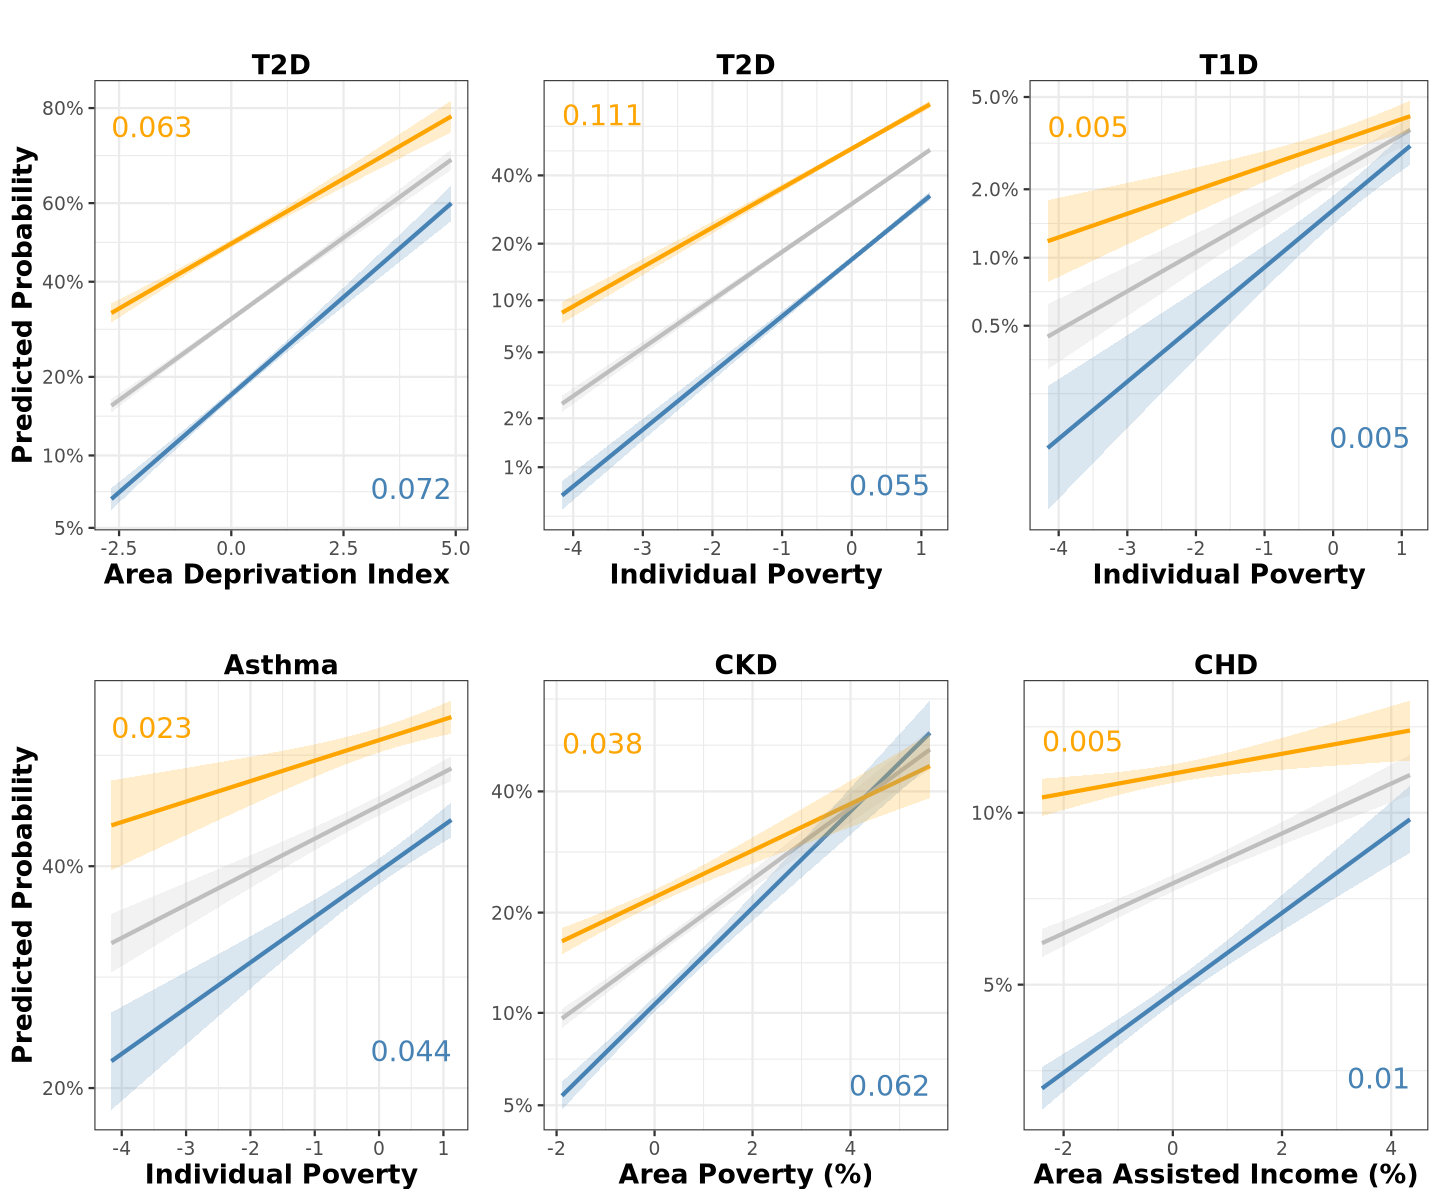

In [31]:
#AB Plot 
library(gridExtra)
library(grid)

options(repr.plot.width = 12, repr.plot.height = 10)  # Set width and height

grid.arrange(
  arrangeGrob(
    A_plot
  ),
  arrangeGrob(
    B_plot 
  
  ),
  arrangeGrob(
    C_plot
  ),
  arrangeGrob(
    D_plot
  ),
  arrangeGrob(
    E_plot
  ),
 arrangeGrob(
    F_plot
  ),
  ncol = 3
)